# Time-normalized whitened spectrogram of SOCAL_H_76_230427_014845.x

The GPL whitened spectrogram is smoothed along time by a Gaussian of width 1 minute. At each time, the mean and standard deviation of that smoothed column, across frequency, shift and scale the original column. A column with standard deviation 0 is left unchanged. The procedure is [spectrogram_time_normalize.md](../spectrogram_time_normalize.md).


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import fftconvolve

from analysis.GPL_Python.gpl_outputs import display_from_spwhiten
from analysis.dict_learning.code.io import discover_windows
from analysis.evaluation.core import _stitch

NPY = Path(
    "/home/yfreund/whale_processing/result/LeiData/"
    "SOCAL_H_76_230427_014845.x.gpl/output/spectrogram_npy"
)
windows = discover_windows(NPY)
windows.sort(key=lambda window: (window.start_sample, window.window_id))
original, _offset = _stitch(NPY)
sec_per_bin = float(windows[0].overlap) / float(windows[0].sample_freq)
sigma = 60.0 / sec_per_bin
radius = max(1, int(np.ceil(4.0 * sigma)))
offsets = np.arange(-radius, radius + 1, dtype=np.float64)
kernel = np.exp(-0.5 * (offsets / sigma) ** 2)
kernel /= kernel.sum()
smoothed = fftconvolve(original, kernel[None, :], mode="same", axes=1)
coverage = np.convolve(np.ones(original.shape[1], dtype=np.float64), kernel, mode="same")
smoothed = smoothed / coverage
mean = smoothed.mean(axis=0)
std = smoothed.std(axis=0)
normalized = np.array(original, copy=True)
good = std > 0.0
normalized[:, good] = (original[:, good] - mean[good]) / std[good]
minutes = np.arange(original.shape[1]) * sec_per_bin / 60.0
freq_axis = np.linspace(0.0, float(windows[0].sample_freq) / 2.0, int(windows[0].fftl) // 2)
i0 = int(np.argmin(np.abs(freq_axis - float(windows[0].start_freq))))
freqs = freq_axis[i0 : i0 + original.shape[0]]
print(
    f"shape {original.shape}  sigma {sigma:.2f} columns ({sigma * sec_per_bin:.2f} s)  "
    f"unchanged columns {int(np.sum(~good))}"
)
print(
    f"original column mean {original.mean(axis=0).mean():.4f}  "
    f"normalized column mean {normalized.mean(axis=0).mean():.4f}"
)


shape (1637, 18270)  sigma 488.28 columns (60.00 s)  unchanged columns 0
original column mean 0.5632  normalized column mean -0.0137


## Mean and standard deviation

Each point is one spectrogram column. Both curves come from the smoothed column, reduced across frequency.


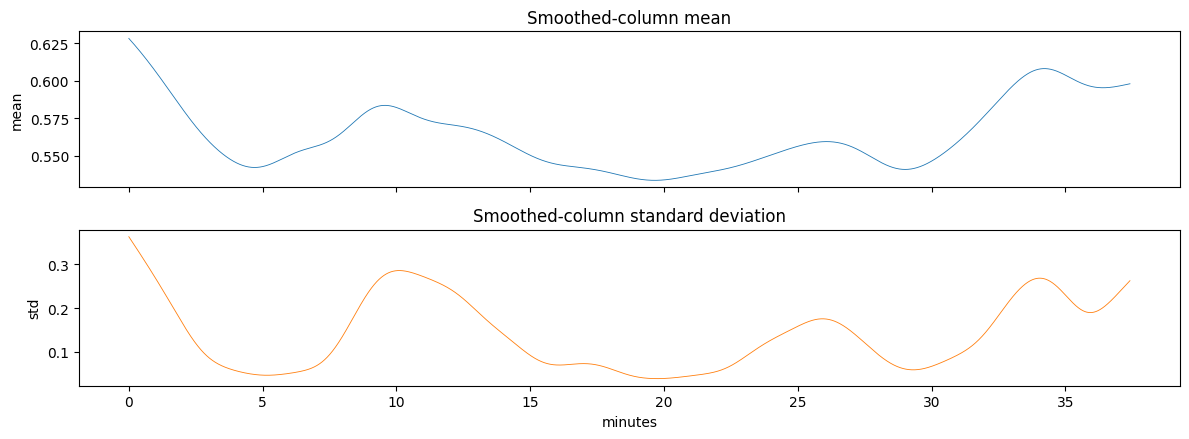

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(12, 4.5), sharex=True)
axes[0].plot(minutes, mean, color="C0", lw=0.6)
axes[0].set_ylabel("mean")
axes[0].set_title("Smoothed-column mean")
axes[1].plot(minutes, std, color="C1", lw=0.6)
axes[1].set_ylabel("std")
axes[1].set_xlabel("minutes")
axes[1].set_title("Smoothed-column standard deviation")
fig.tight_layout()
plt.show()


## Spectrogram, 19 to 21 minutes

Both panels are the cube root of the absolute value, from 0 to 500 Hz, drawn with the jet colormap. Each panel's color range is the minimum and maximum of the pixels in that panel, so no pixel is clipped. The top panel is the whitened spectrogram. The bottom panel is the same interval after subtracting `mean(t)` and dividing by `std(t)`.


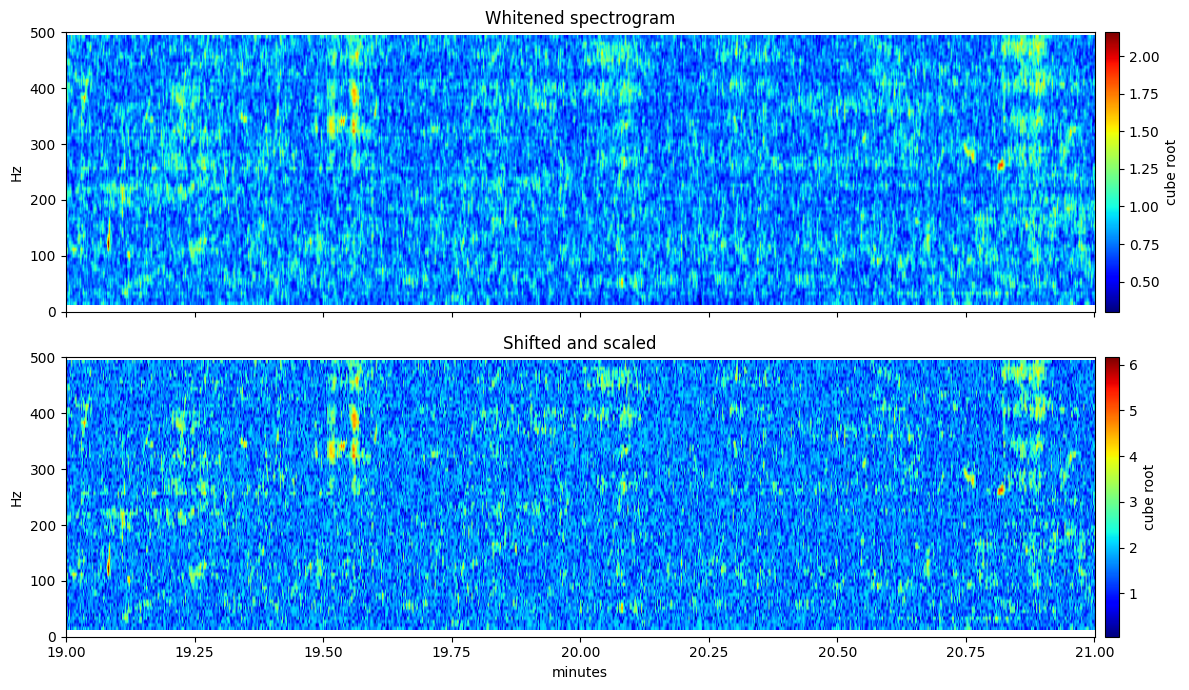

window columns 9277:10254  original rms 0.6025  normalized rms 7.1691


In [3]:
lo_min, hi_min = 19.0, 21.0
lo = int(np.floor(lo_min * 60.0 / sec_per_bin))
hi = int(np.ceil(hi_min * 60.0 / sec_per_bin))
band = np.flatnonzero(freqs <= 500.0)
f_lo = float(freqs[int(band[0])])
f_hi = float(freqs[int(band[-1])])
t_left = lo * sec_per_bin / 60.0
t_right = hi * sec_per_bin / 60.0

def show(ax, data, title):
    shown = display_from_spwhiten(data[int(band[0]) : int(band[-1]) + 1, lo:hi])
    lo_v = float(np.min(shown))
    hi_v = float(np.max(shown))
    im = ax.imshow(
        shown,
        origin="lower",
        aspect="auto",
        cmap="jet",
        vmin=lo_v,
        vmax=hi_v,
        extent=[t_left, t_right, f_lo, f_hi],
    )
    ax.set_ylim(0.0, 500.0)
    ax.set_ylabel("Hz")
    ax.set_title(title)
    return im

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
im0 = show(axes[0], original, "Whitened spectrogram")
im1 = show(axes[1], normalized, "Shifted and scaled")
axes[1].set_xlabel("minutes")
fig.colorbar(im0, ax=axes[0], fraction=0.02, pad=0.01, label="cube root")
fig.colorbar(im1, ax=axes[1], fraction=0.02, pad=0.01, label="cube root")
fig.tight_layout()
plt.show()
print(
    f"window columns {lo}:{hi}  "
    f"original rms {np.sqrt(np.mean(original[:, lo:hi] ** 2)):.4f}  "
    f"normalized rms {np.sqrt(np.mean(normalized[:, lo:hi] ** 2)):.4f}"
)
